## 05 - Model selection

Before training the final model I compare a few BERTopic settings: different values of `min_cluster_size` (HDBSCAN) and `min_df` (CountVectorizer). The results explain the values used in 06. No model is saved here.

Four more comparisons follow, with the settings of 06 kept fixed: `min_samples` (HDBSCAN), the UMAP seed, the embedding model and the keyword settings. They describe how the current setup behaves; nothing in 06 is changed by them.

Input: `data/processed/trenord_reviews_clean.csv` (Italian reviews only), and `data/processed/trenord_reviews_topics.csv` only to check that seed 42 reproduces the topics of 06
Output: comparison tables in this notebook

In [1]:
# --- IMPORTS ---
import time

import matplotlib.pyplot as plt
import pandas as pd
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score
from spacy.lang.it.stop_words import STOP_WORDS as italian_stopwords
from umap import UMAP

# Define the minimum reviews per topic.
MIN_CLUSTER_SIZES = [20, 25, 30, 40, 50]
# Define the minimum document frequency each term must have to be considered a keyword.
MIN_DF_VALUES = [1, 2, 5]
# Values of HDBSCAN min_samples to compare. 30 is the value 06 uses without setting it.
MIN_SAMPLES_VALUES = [5, 10, 15, 30]
# UMAP seeds to compare. 42 is the seed of 06.
UMAP_SEEDS = [42, 0, 1, 2, 3]
# Words added to the stopwords in the keyword comparison
EXTRA_STOPWORDS = ["app", "applicazione"]

W1105 13:49:09.607000 34780 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# --- LOAD DATA AND PREPARE TEXTS ---
# Load the cleaned reviews dataset and filter for Italian reviews.
df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")
italian_df = df[df["language"] == "it"].copy()
# Prepare the texts for BERTopic by converting the "text_clean" column to a list.
texts = italian_df["text_clean"].tolist()

# Validate the texts to ensure they are non-empty strings. If a text is invalid, replace it with a single space.
# BERTopic requires non-empty strings for processing, so this step ensures that all texts are valid.
for i in range(len(texts)):
    text = texts[i]
    is_valid = isinstance(text, str) and len(text.strip()) > 0
    if not is_valid:
        texts[i] = " "

print(f"Italian reviews: {len(texts)}")

Italian reviews: 6951


In [3]:
# --- SENTENCE EMBEDDINGS (computed once) ---
# Load the multilingual sentence transformer model for generating embeddings.
embedding_model = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")
# Encode each review into a vector representation (embedding) of 768 dimensions using the model 
# and the output is a 2D array where each row corresponds to a review and each column 
# corresponds to a dimension in the embedding space.
# The encoding is timed, so it can be compared with other embedding models at the end.
start_time = time.perf_counter()
embeddings = embedding_model.encode(texts, show_progress_bar=False)
mpnet_encoding_seconds = time.perf_counter() - start_time

print(f"Embeddings: {embeddings.shape[0]} reviews x {embeddings.shape[1]} dimensions")
print(f"Encoding time: {mpnet_encoding_seconds:.0f} s")

Loading weights: 100%|██████████| 199/199 [00:03<00:00, 59.54it/s]


Embeddings: 6951 reviews x 768 dimensions
Encoding time: 177 s


In [4]:
# --- TOKENIZED CORPUS FOR COHERENCE ---
# Coherence checks how often the top words of a topic appear together in the reviews.

# CountVectorizer is a tool that converts a collection of text documents into a matrix of token counts. 
# Remove stopwords and consider unigrams and bigrams.
coherence_vectorizer = CountVectorizer(stop_words=list(italian_stopwords), ngram_range=(1, 2))
# The analyzer is a function that splits the text into tokens (words or bigrams) based on the settings of the CountVectorizer.
analyzer = coherence_vectorizer.build_analyzer()

tokenized_texts = []
for text in texts:
    tokenized_texts.append(analyzer(text))

# Dictionary is a Gensim class that maps each unique token to a unique integer ID. 
# It will be used to calculate the coherence of the topics generated by BERTopic.
dictionary = Dictionary(tokenized_texts)

print(f"Tokenized reviews: {len(tokenized_texts)}")
print(f"Distinct tokens  : {len(dictionary)}")

# How the analyzer splits a text: a made-up sentence, not a real review
example_text = "non riesco ad acquistare i biglietti dalla app"
print(analyzer(example_text))

Tokenized reviews: 6951
Distinct tokens  : 52520
['riesco', 'acquistare', 'biglietti', 'app', 'riesco acquistare', 'acquistare biglietti', 'biglietti app']


In [5]:
# --- Function to train a BERTopic model with specified parameters ---

def train_topic_model(min_cluster_size, min_df, run_embeddings=None, run_embedding_model=None,
                      umap_random_state=42, min_samples=None, extra_stopwords=None,
                      representation_model=None):
    # Everything except min_cluster_size and min_df is the same as in 06. Each run gets
    # fresh model objects, because BERTopic fits them in place.
    # The other parameters are used only by the comparisons at the end of the notebook.
    # Left at their default values, they give exactly the setup of 06:
    # - run_embeddings, run_embedding_model: None means the mpnet embeddings and model loaded above
    # - umap_random_state: 42, the seed of 06
    # - min_samples: None, so HDBSCAN uses min_cluster_size, as in 06
    # - extra_stopwords: None, so only the spaCy Italian stopwords are removed
    # - representation_model: None means MMR with diversity 0.3
    if run_embeddings is None:
        run_embeddings = embeddings
    if run_embedding_model is None:
        run_embedding_model = embedding_model

    stopwords = list(italian_stopwords)
    if extra_stopwords is not None:
        for word in extra_stopwords:
            stopwords.append(word)

    if representation_model is None:
        representation_model = MaximalMarginalRelevance(diversity=0.3)

    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=umap_random_state)
    hdbscan_model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples, metric="euclidean", prediction_data=True)
    vectorizer_model = CountVectorizer(stop_words=stopwords, min_df=min_df, ngram_range=(1, 2))

    topic_model = BERTopic(
        # The embedding model is also used by MMR and KeyBERTInspired to compare the keywords
        embedding_model=run_embedding_model,
        umap_model=umap_model, # For each review, it looks for the 15 closest reviews in the 768-dimensional embedding space, then reduces every review to 5 dimensions.
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model, # CountVectorizer builds the candidate keywords from the reviews, removing Italian stopwords and considering unigrams and bigrams.
        representation_model=representation_model, # MaximalMarginalRelevance avoids repetition in the top keywords of a topic by selecting words that are both relevant and diverse.
        top_n_words=10, # The number of top words to extract for each topic. These words are used to represent the topic and are also used in coherence calculations.
        language="multilingual",
        calculate_probabilities=False,
        verbose=False
    )

    # Passing the embeddings skips the encoding step inside BERTopic
    topics_before, _ = topic_model.fit_transform(texts, embeddings=run_embeddings)

    # Outliers are reassigned to the closest topic, as in 06.
    # BERTopic stops with an error if there is no outlier to reassign, which can happen with
    # another embedding model, so in that case the topics are kept as they are.
    if -1 in topics_before:
        topics_after = topic_model.reduce_outliers(
            texts,
            topics_before,
            strategy="embeddings",
            threshold=0.0,
            embeddings=run_embeddings
        )
    else:
        topics_after = topics_before
    topic_model.update_topics(
        texts,
        topics=topics_after,
        vectorizer_model=vectorizer_model,
        representation_model=representation_model
    )
    return topic_model, topics_before, topics_after

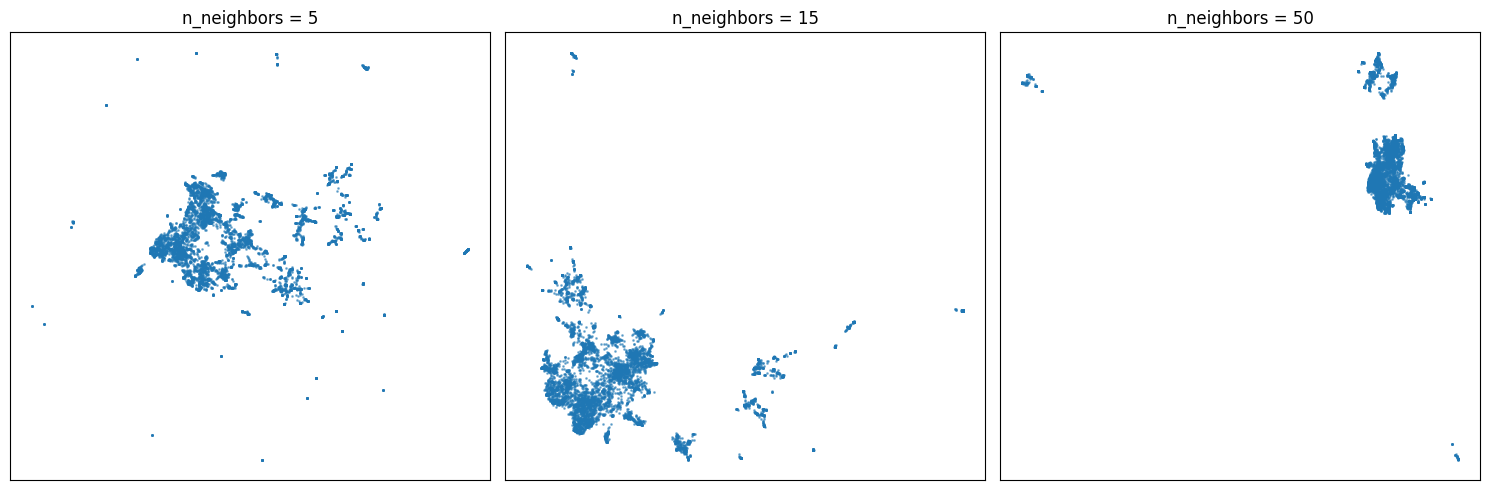

In [6]:
# --- Visualize the effect of n_neighbors on UMAP embeddings ---
# UMAP down to 2 dimensions only to draw the reviews on a plane.
# Each dot is a review. Same embeddings, three values of n_neighbors.
neighbor_values = [5, 15, 50]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i in range(len(neighbor_values)):
    n = neighbor_values[i]
    reducer = UMAP(n_neighbors=n, n_components=2, min_dist=0.0, metric="cosine", random_state=42)
    points = reducer.fit_transform(embeddings)

    axes[i].scatter(points[:, 0], points[:, 1], s=1, alpha=0.5)
    axes[i].set_title(f"n_neighbors = {n}")
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.tight_layout()
plt.show()

In [7]:
# --- ONE TRIAL MODEL ---
# Train one model with the following values (min_cluster_size=30, min_df=5),
# so each metric below can be tried on a real model as soon as it is defined.
# The function train_topic_model (defined above) returns three things:
# - model: the trained BERTopic model
# - topics_before: one topic number per review, as HDBSCAN found them.
# -1 means the review did not fit any group (an outlier)
# - topics_after: the same list after the outliers were moved to the closest topic,
#   so no review has -1 anymore
model, topics_before, topics_after = train_topic_model(min_cluster_size=30, min_df=5)

# The 10 keywords of topic 0 with their c-TF-IDF weight.
# A higher weight means the word is more typical of this topic than of the others.
print("Keywords of topic 0:")
for word, weight in model.get_topic(0):
    print(f"  {word:<25} {weight:.3f}")

# The first 10 reviews: their topic before and after the outliers were reassigned
# int() turns numpy integers into plain numbers, so the lists print as [1, 1, 0, ...]
first_topics_before = []
first_topics_after = []
for i in range(10):
    first_topics_before.append(int(topics_before[i]))
    first_topics_after.append(int(topics_after[i]))
print("\nTopics before (first 10 reviews):", first_topics_before)
print("Topics after  (first 10 reviews):", first_topics_after)

# How many reviews were outliers before, and how many after
print(f"\nOutliers before: {topics_before.count(-1)}")
print(f"Outliers after : {list(topics_after).count(-1)}")

2026-11-05 13:53:18,898 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Keywords of topic 0:
  treni                     0.065
  treno                     0.052
  ritardi                   0.031
  app                       0.026
  stazione                  0.025
  servizio                  0.020
  orari treni               0.013
  treni ritardo             0.013
  cancellazioni             0.012
  aggiornata                0.011

Topics before (first 10 reviews): [1, 1, 0, 19, 3, 4, 5, 3, 26, -1]
Topics after  (first 10 reviews): [1, 1, 0, 19, 3, 4, 5, 3, 26, 13]

Outliers before: 1601
Outliers after : 0


In [8]:
# --- METRIC 1: OUTLIERS ---
# Share of reviews that HDBSCAN could not put in any topic (topic -1).
# It is computed on topics_before, because after the reassignment there are no outliers left.
def outlier_share(topics_before):
    n_outliers = topics_before.count(-1)
    return n_outliers / len(topics_before) * 100

# Try it on the trial model: expected 23.0% for min_cluster_size=30
print(f"Outliers before reduction: {outlier_share(topics_before):.1f}%")

Outliers before reduction: 23.0%


In [9]:
# --- METRIC 2: LARGEST TOPIC ---
# Share of reviews in the biggest topic, computed on topics_after (the final assignments).
# A very high value means the model put almost everything in one topic and stopped telling the themes apart.
def largest_topic_share(topics_after):
    # value_counts() counts the reviews of each topic; max() takes the biggest topic
    topic_sizes = pd.Series(topics_after).value_counts()
    return topic_sizes.max() / len(topics_after) * 100

# Print the share of reviews in the largest topic for the trial model.
print(f"Largest topic: {largest_topic_share(topics_after):.1f}% of the reviews")

Largest topic: 17.5% of the reviews


In [10]:
# --- TOP WORDS OF EACH TOPIC ---
# Collects the keywords of every topic in one list per topic.
# Coherence and diversity, the next two metrics, are computed on these words.
def get_top_words(topic_model):
    top_words = []
    for topic_id in topic_model.get_topics():
        # -1 is not a real topic, it holds the outliers
        if topic_id == -1:
            continue
        words = []
        # get_topic returns (word, weight) pairs; only the word is needed here
        for word, weight in topic_model.get_topic(topic_id)[:10]:
            # BERTopic fills missing keywords with empty strings
            if word != "":
                words.append(word)
        top_words.append(words)
    return top_words

# Now we print the number of topics and the top words of the first topic for the trial model.
top_words = get_top_words(model)
print(f"Topics: {len(top_words)}")
print(f"Top words of the first topic: {top_words[0]}")

Topics: 30
Top words of the first topic: ['treni', 'treno', 'ritardi', 'app', 'stazione', 'servizio', 'orari treni', 'treni ritardo', 'cancellazioni', 'aggiornata']


In [11]:
# --- METRIC 3: COHERENCE ---
# Checks whether the top words of each topic really appear together in the reviews.
# A high value means the words of a topic go together; a low value means they are a mix.
def coherence_score(top_words):
    # gensim stops on words that are not in the dictionary, so they are left out
    words_in_dictionary = []
    for words in top_words:
        kept = []
        for word in words:
            if word in dictionary.token2id:
                kept.append(word)
        words_in_dictionary.append(kept)

    coherence_model = CoherenceModel(
        topics=words_in_dictionary,   # the top words of each topic
        texts=tokenized_texts,        # the reviews split into tokens
        dictionary=dictionary,        # the mapping of tokens to IDs
        coherence="c_v",              # the coherence measure to use
        processes=1                   # more processes can hang when started from a notebook on Windows
    )
    # Average over all topics, between 0 and 1
    return coherence_model.get_coherence()

print(f"Coherence c_v: {coherence_score(top_words):.3f}")

Coherence c_v: 0.419


In [12]:
# --- METRIC 4: DIVERSITY ---
# Checks how different the topics are from each other: the share of top words
# that are unique across all topics. 1.0 means no word is shared between topics.
def diversity_score(top_words):
    # Put the top words of all topics in one list (for 30 topics with 10 words each, 300 words)
    all_words = []
    for words in top_words:
        all_words.extend(words)
    # set() removes the duplicates, so its length is the number of distinct words
    return len(set(all_words)) / len(all_words)

# Try it on the trial model: expected 0.783 for min_cluster_size=30
print(f"Diversity: {diversity_score(top_words):.3f}")

Diversity: 0.783


In [13]:
# --- ALL METRICS FOR ONE MODEL ---
# Puts all the metrics of one model together. The comparison below calls this
# function once for every value tried, and each result becomes a row of the table.
def compute_metrics(topic_model, topics_before, topics_after):
    top_words = get_top_words(topic_model)

    # Two checks that tell whether the coherence can be trusted:
    # words that are not in the dictionary (left out of the coherence)
    # and empty slots (topics with fewer than 10 keywords)
    words_not_found = 0
    n_words = 0
    for words in top_words:
        n_words += len(words)
        for word in words:
            if word not in dictionary.token2id:
                words_not_found += 1
    empty_words = len(top_words) * 10 - n_words

    # One name and one value per metric: each pair becomes a column of the table
    return {
        "topics": len(top_words),
        "outliers before reduction (%)": round(outlier_share(topics_before), 1),
        "largest topic (%)": round(largest_topic_share(topics_after), 1),
        "coherence c_v": round(coherence_score(top_words), 3),
        "diversity": round(diversity_score(top_words), 3),
        "topic words not found": words_not_found,
        "empty topic words": empty_words,
    }

# Try it on the trial model: these are the values of the min_cluster_size=30 row
metrics = compute_metrics(model, topics_before, topics_after)
for name, value in metrics.items():
    print(f"  {name:<32} {value}")

  topics                           30
  outliers before reduction (%)    23.0
  largest topic (%)                17.5
  coherence c_v                    0.419
  diversity                        0.783
  topic words not found            0
  empty topic words                0


In [14]:
# --- TRAIN ONE MODEL PER min_cluster_size ---
# One model for each value in MIN_CLUSTER_SIZES. min_df stays at 5 in every run,
# so any difference in the results comes from min_cluster_size alone.
runs = {}

for min_cluster_size in MIN_CLUSTER_SIZES:
    topic_model, run_topics_before, run_topics_after = train_topic_model(min_cluster_size, min_df=5)
    # Keep the model and its topic lists, so the metrics can be computed in the next cell
    runs[min_cluster_size] = {
        "model": topic_model,
        "topics_before": run_topics_before,
        "topics_after": run_topics_after,
    }

2026-11-05 13:53:49,564 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:54:21,299 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:54:46,791 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF em

In [15]:
# --- METRICS FOR EACH min_cluster_size ---
# Computes the metrics of the five models trained above and puts them in one table,
# one row per value of min_cluster_size.
rows = []

for min_cluster_size in MIN_CLUSTER_SIZES:
    run = runs[min_cluster_size]
    metrics = compute_metrics(run["model"], run["topics_before"], run["topics_after"])
    # Each row starts with the value tried, followed by its metrics
    row = {"min_cluster_size": min_cluster_size}
    row.update(metrics)
    rows.append(row)

# Each dictionary becomes a row and each key a column
results = pd.DataFrame(rows).set_index("min_cluster_size")
results

,topics,outliers before reduction (%),largest topic (%),coherence c_v,diversity,topic words not found,empty topic words
min_cluster_size,,,,,,,
20,55,26.5,14.8,0.416,0.703,0,5
25,37,17.8,28.6,0.421,0.684,0,0
30,30,23.0,17.5,0.419,0.783,0,0
40,8,1.7,85.9,0.348,0.212,0,14
50,6,1.8,85.9,0.497,0.192,0,34


### Reading the min_cluster_size table

`min_cluster_size` is the minimum number of reviews a group needs to become a topic. Smaller groups join a bigger one or become outliers.

- Higher values give fewer topics: 55 with 20, 6 with 50.
- 40 and 50 collapse: one topic holds 86% of the reviews and diversity drops. The high coherence of 50 comes from a few generic words, not from better topics.
- 20, 25 and 30 have almost the same coherence, so the other columns decide. 20 has many overlapping topics and more outliers, 25 has one topic with almost a third of the reviews. 30 has the best diversity and no dominant topic.

We keep 30, the value used in 06. Between 30 and 40 the number of topics drops from 30 to 8, so the model is very sensitive in that range.

### Keyword filter: min_df

In BERTopic the vectorizer is fitted on one joined document per topic, so `min_df` counts topics, not reviews, and it
changes only the keywords of each topic, not which reviews belong to which topic. The runs below use `min_cluster_size=30`.

In [16]:
# --- TRAIN ONE MODEL PER min_df (min_cluster_size=30) ---
# One model for each value in MIN_DF_VALUES. min_cluster_size stays at 30, the value
# chosen with the table above, so only min_df changes between runs.
# min_df only changes the keywords: the reviews in each topic should stay the same.
min_df_runs = {}

for min_df in MIN_DF_VALUES:
    topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=min_df)
    # Keep the model and its topic lists for the next cells
    min_df_runs[min_df] = {
        "model": topic_model,
        "topics_before": run_topics_before,
        "topics_after": run_topics_after,
    }

2026-11-05 13:55:33,918 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:55:58,595 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:56:21,679 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF em

In [17]:
# --- SAME TOPIC ASSIGNMENTS FOR EVERY min_df ---
# min_df only filters the words that can become keywords, so every review should
# keep its topic whatever the value. min_df=5 (the value used in 06) is the reference.
# list() turns the result into a plain list, so == compares the two lists as a whole.
reference_topics = list(min_df_runs[5]["topics_after"])

for min_df in MIN_DF_VALUES:
    if min_df == 5:
        continue  # the reference itself
    same_topics = list(min_df_runs[min_df]["topics_after"]) == reference_topics
    if same_topics:
        result = "PASS"
    else:
        result = "FAIL"
    print(f"{result}  min_df={min_df}: same topic for every review as min_df=5")

# The min_df=5 run uses the same settings as the min_cluster_size=30 run above,
# so the two must give exactly the same topics
same_as_first_comparison = reference_topics == list(runs[30]["topics_after"])
if same_as_first_comparison:
    result = "PASS"
else:
    result = "FAIL"
print(f"{result}  min_df=5: same topic for every review as min_cluster_size=30 above")

PASS  min_df=1: same topic for every review as min_df=5
PASS  min_df=2: same topic for every review as min_df=5
PASS  min_df=5: same topic for every review as min_cluster_size=30 above


In [18]:
# --- METRICS FOR EACH min_df ---
# Only the metrics that depend on the keywords are kept. Number of topics, outliers
# and largest topic are the same for every min_df, as the check above showed.
min_df_rows = []

for min_df in MIN_DF_VALUES:
    run = min_df_runs[min_df]
    metrics = compute_metrics(run["model"], run["topics_before"], run["topics_after"])
    min_df_rows.append({
        "min_df": min_df,
        "coherence c_v": metrics["coherence c_v"],
        "diversity": metrics["diversity"],
        "empty topic words": metrics["empty topic words"],
        # Words not found in any single review: fake word pairs made by joining reviews
        "topic words not found": metrics["topic words not found"],
    })

min_df_results = pd.DataFrame(min_df_rows).set_index("min_df")
min_df_results

,coherence c_v,diversity,empty topic words,topic words not found
min_df,,,,
1,0.385,0.887,0,49
2,0.409,0.863,0,20
5,0.419,0.783,0,0


### Reading the min_df table

`min_df` only changes the keywords, not the reviews in each topic, so this table keeps only the metrics that depend on the keywords.

What "topic words not found" means. These are keywords that do not appear in any single review. They come from how BERTopic picks keywords: it joins all the reviews of a topic into one long text. For example, "app ottima" and "ottima davvero" become "app ottima ottima davvero", which contains the pair "ottima ottima". No user wrote it: it exists only because two reviews were joined. These fake pairs are left out of the coherence.

What the table shows.
- `min_df=1` looks best at first, with the highest diversity, but 49 of its keywords are fake pairs.
- `min_df=2` still has 20.
- `min_df=5` has none, and the highest coherence. Fake pairs are rare, so they do not reach five topics and the filter removes them.

We keep `min_df=5`, the value used in 06. The cost is that a real word found in fewer than five topics can also be dropped from the keywords.

In [19]:
# --- TOP 5 KEYWORDS OF FIVE TOPICS, SIDE BY SIDE ---
# Shows how min_df changes the keywords of the same topics.
# Topic ids are the same for every min_df, because the reviews stay in the same topics.
# These topics were chosen so that none of the keywords shown is a personal name or a code.
TOPICS_TO_SHOW = [5, 9, 10, 14, 26]

# Show the full keyword lists instead of cutting them at 50 characters
pd.set_option("display.max_colwidth", None)

# One row per topic, one column per min_df value
keyword_rows = []
for topic_id in TOPICS_TO_SHOW:
    row = {"topic": topic_id}
    for min_df in MIN_DF_VALUES:
        words = []
        for word, weight in min_df_runs[min_df]["model"].get_topic(topic_id)[:5]:
            words.append(word)
        # Join the five words into one string, e.g. "password, login, account, ..."
        row[f"min_df={min_df}"] = ", ".join(words)
    keyword_rows.append(row)

keywords_table = pd.DataFrame(keyword_rows).set_index("topic")
keywords_table

,min_df=1,min_df=2,min_df=5
topic,,,
5,"password, login, account, app, errore","password, login, account, accesso, errore","login, account, accesso, errore, mail"
9,"utile utile, ottima applicazione, utile funzionale, funzionale ottima, utilissima","funzionale, ottima applicazione, utile funzionale, funzionale ottima, applicazione utile","ottima applicazione, applicazione, utilissima, applicazione utile, efficace"
10,"ottima ottima, perfetto ottima, ottimale ottima, bellissimo perfetta, spettacolare ottima","ottima ottima, ottima, fantastica ottima, ottimale, ottimo sevizio","ottima, perfetta, perfetto, fantastica, bellissima"
14,"ottimo ottimo, ottimo ok, buono ottimo, servizio ottimo, ottimo buona","ottimo servizio, ottima esperienza, buon servizio, complimenti ottimo, ottimo supporto","ottimo, ottimo servizio, buono, complimenti, servizio"
26,"funziona funziona, accedere funziona, funziona impossibile, comando disconnettersi, bug funziona","funziona impossibile, utilizzare tap, accesso funziona, risolvendo problema, settimana funziona","funziona, accedere, assistenza, accesso, impossibile utilizzare"


What the table contains. The keywords of five topics, under the three values of `min_df`.

- Rows: one row per topic. The number in the `topic` column is the topic id. The id refers to the same group of reviews in every column, because `min_df` does not move reviews between topics.
- Columns: one column per value of `min_df` (1, 2 and 5). Everything else in the model is the same.
- Cells: the top 5 keywords of that topic with that `min_df`, ordered from the most typical to the least typical.

To read it, follow a row from left to right: the reviews stay the same, only the words chosen to describe them change.

What it shows.
- Fake word pairs at low `min_df`. With `min_df=1` many keywords are repeated words such as "ottima ottima", "ottimo ottimo" and "perfetto ottima" (topics 10 and 14). No user wrote them: they appear only because BERTopic joins the reviews of a topic into one text before picking keywords. Topic 10 with `min_df=1` is made almost only of these pairs.
- Rare words pass the filter at low `min_df`. With `min_df=2`, topic 10 includes "sevizio", a typo of "servizio" written by a few users. With `min_df=5` it disappears.
- Cleaner keywords at `min_df=5`. The same topics are described by plain, readable words: "ottima, perfetta, perfetto, fantastica, bellissima" for topic 10, "funziona, accedere, assistenza, accesso, impossibile utilizzare" for topic 26.
- The cost of `min_df=5`. In topic 5, about login problems, "password" is a keyword with `min_df=1` and `min_df=2` but not with `min_df=5`, because it appears in fewer than five topics. The topic is still clear from "login, account, accesso", but a specific word is lost.

Conclusion. `min_df=5` gives the clearest keywords and removes the fake pairs, at the cost of a few specific words. It is the value used in 06.

### Comparison 1: min_samples

`min_samples` is the second HDBSCAN parameter. It sets how strict the clustering is about dense areas: a review is the core of a dense area only if at least `min_samples` points, itself included, are close to it. It changes which reviews HDBSCAN keeps in a group and which it leaves out as outliers.

06 does not set it. In that case the hdbscan library uses `min_cluster_size` instead, so the effective value in 06 is 30. This also means that in the first table `min_samples` changed together with `min_cluster_size`: the run with 20 had `min_samples=20`, the run with 50 had `min_samples=50`.

Here `min_cluster_size=30` and `min_df=5` stay fixed and only `min_samples` changes: 5, 10, 15 and 30.

In [20]:
# --- TRAIN ONE MODEL PER min_samples (min_cluster_size=30, min_df=5) ---
min_samples_runs = {}

for min_samples in MIN_SAMPLES_VALUES:
    topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=5, min_samples=min_samples)
    min_samples_runs[min_samples] = {
        "model": topic_model,
        "topics_before": run_topics_before,
        "topics_after": run_topics_after,
    }

2026-11-05 13:56:52,443 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:57:25,158 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:57:54,586 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF em

In [21]:
# --- min_samples=30 IS THE SAME AS NOT SETTING IT ---
# If the library really uses min_cluster_size when min_samples is not given,
# min_samples=30 must give the same topic for every review as the min_cluster_size=30 run above.
same_topics = list(min_samples_runs[30]["topics_after"]) == list(runs[30]["topics_after"])
if same_topics:
    result = "PASS"
else:
    result = "FAIL"
print(f"{result}  min_samples=30: same topic for every review as min_cluster_size=30 without min_samples")

PASS  min_samples=30: same topic for every review as min_cluster_size=30 without min_samples


In [22]:
# --- METRICS FOR EACH min_samples ---
# Same metrics as the first table, one row per value of min_samples.
min_samples_rows = []

for min_samples in MIN_SAMPLES_VALUES:
    run = min_samples_runs[min_samples]
    metrics = compute_metrics(run["model"], run["topics_before"], run["topics_after"])
    row = {"min_samples": min_samples}
    row.update(metrics)
    min_samples_rows.append(row)

min_samples_results = pd.DataFrame(min_samples_rows).set_index("min_samples")
min_samples_results

,topics,outliers before reduction (%),largest topic (%),coherence c_v,diversity,topic words not found,empty topic words
min_samples,,,,,,,
5,54,32.6,8.1,0.436,0.681,0,0
10,45,27.4,13.8,0.430,0.696,0,0
15,38,17.7,18.6,0.438,0.721,0,0
30,30,23.0,17.5,0.419,0.783,0,0


### Reading the min_samples table

- Smaller values give more topics: 54 with 5, 45 with 10, 38 with 15 and 30 with 30.
- The outlier share does not move in one direction: 32.6% with 5, 27.4% with 10, 17.7% with 15 and 23.0% with 30.
- The largest topic holds 8.1% of the reviews with 5 and between 13.8% and 18.6% with the other values.
- Coherence stays between 0.419 and 0.438. Diversity grows with `min_samples`, from 0.681 with 5 to 0.783 with 30.
- No run has topic words not found or empty slots.

The row for 30 is the same as the `min_cluster_size=30` row of the first table, as the check above showed.

### Comparison 2: UMAP seed

UMAP starts from a random layout and improves it step by step. The seed (`random_state`) fixes that random start, so the same seed always gives the same result. A different seed gives a slightly different layout, and HDBSCAN can then draw the groups differently.

This comparison trains the current setup with five seeds: 42 (the seed of 06), 0, 1, 2 and 3. The embeddings are the same in every run, so the seed is the only thing that changes. If the topics are stable, the results should be close to those of seed 42.

To compare the assignments I use the adjusted Rand index (ARI). It looks at every pair of reviews and checks whether two runs agree on putting them in the same topic or in different topics. 1 means the two runs group the reviews in exactly the same way, even if the topic numbers are different; 0 means no more agreement than random groups. It is computed on the final assignments, after the outliers are reassigned.

In [23]:
# --- TRAIN ONE MODEL PER UMAP SEED (min_cluster_size=30, min_df=5) ---
seed_runs = {}

for seed in UMAP_SEEDS:
    topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=5, umap_random_state=seed)
    seed_runs[seed] = {
        "model": topic_model,
        "topics_before": run_topics_before,
        "topics_after": run_topics_after,
    }

2026-11-05 13:58:45,507 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:59:09,319 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 13:59:31,720 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF em

In [24]:
# --- SEED 42 REPRODUCES THE TOPICS OF 06 ---
# trenord_reviews_topics.csv holds the topic that 06 gave to each Italian review.
# The rows must be the same reviews in the same order, then the topics must match one by one.
saved_topics_df = pd.read_csv("../data/processed/trenord_reviews_topics.csv")

same_reviews = saved_topics_df["review_id"].tolist() == italian_df["review_id"].tolist()
same_topics = saved_topics_df["topic"].tolist() == list(seed_runs[42]["topics_after"])

print(f"Reviews in trenord_reviews_topics.csv: {len(saved_topics_df):,}")
if same_reviews:
    print("PASS  same reviews in the same order as here")
else:
    print("FAIL  the reviews are not the same as here")
if same_topics:
    print("PASS  seed 42: same topic for every review as trenord_reviews_topics.csv")
else:
    print("FAIL  seed 42: some reviews have a different topic from trenord_reviews_topics.csv")

Reviews in trenord_reviews_topics.csv: 6,951
PASS  same reviews in the same order as here
PASS  seed 42: same topic for every review as trenord_reviews_topics.csv


In [25]:
# --- METRICS AND ARI FOR EACH SEED ---
# The ARI compares each seed with seed 42, so the seed 42 row is 1.0 by definition.
reference_topics = list(seed_runs[42]["topics_after"])
seed_rows = []

for seed in UMAP_SEEDS:
    run = seed_runs[seed]
    metrics = compute_metrics(run["model"], run["topics_before"], run["topics_after"])
    ari = adjusted_rand_score(reference_topics, list(run["topics_after"]))
    seed_rows.append({
        "UMAP seed": seed,
        "topics": metrics["topics"],
        "outliers before reduction (%)": metrics["outliers before reduction (%)"],
        "largest topic (%)": metrics["largest topic (%)"],
        "coherence c_v": metrics["coherence c_v"],
        "diversity": metrics["diversity"],
        "ARI vs seed 42": round(ari, 3),
    })

seed_results = pd.DataFrame(seed_rows).set_index("UMAP seed")
seed_results

,topics,outliers before reduction (%),largest topic (%),coherence c_v,diversity,ARI vs seed 42
UMAP seed,,,,,,
42,30,23.0,17.5,0.419,0.783,1.000
0,33,29.1,10.1,0.434,0.767,0.667
1,27,18.2,19.3,0.415,0.756,0.885
2,31,22.5,17.1,0.418,0.735,0.793
3,27,14.2,32.6,0.426,0.726,0.515


### Reading the seed table

Seed 42 reproduces the topics of 06 exactly, as the check above showed. The other seeds use the same embeddings and the same settings.

- The number of topics goes from 27 to 33, and the outlier share before reduction from 14.2% to 29.1%.
- The largest topic holds between 10.1% (seed 0) and 32.6% (seed 3) of the reviews.
- Coherence stays between 0.415 and 0.434, and diversity between 0.726 and 0.783.
- The ARI against seed 42 goes from 0.515 (seed 3) to 0.885 (seed 1). None of the other seeds groups the reviews exactly as seed 42 does.

### Comparison 3: embedding models

The embedding model turns each review into a list of numbers, and everything after it (UMAP, HDBSCAN) works on those numbers. Models trained on different data or with a different size place the reviews differently, so they can lead to different topics.

Three multilingual models are compared, all with the settings of 06 (`min_cluster_size=30`, `min_df=5`, UMAP seed 42):
- `paraphrase-multilingual-mpnet-base-v2`, the current model;
- `paraphrase-multilingual-MiniLM-L12-v2`, a smaller model from the same family;
- `intfloat/multilingual-e5-base`, a model of a different family.

Each text is prepared as its model card asks. The two paraphrase models take the text as it is. The e5 model card asks for a prefix on every text and says to use `"query: "` for tasks that are not retrieval, and its example normalizes the embeddings, so both are done here. MMR also uses the embedding model to compare the keywords, and it passes the words without prefix.

The embeddings of each model are computed once and kept only in memory. The ARI compares each model's assignments with those of the current model (seed 42 above).

In [26]:
# --- EMBEDDINGS OF THE OTHER TWO MODELS (computed once each, not saved) ---
# The current model's embeddings and encoding time come from the cell at the top.
embedding_runs = {
    "paraphrase-multilingual-mpnet-base-v2": {
        "model": embedding_model,
        "embeddings": embeddings,
        "seconds": mpnet_encoding_seconds,
    }
}

# MiniLM: same family as mpnet, the text is passed as it is
minilm_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
start_time = time.perf_counter()
minilm_embeddings = minilm_model.encode(texts, show_progress_bar=False)
embedding_runs["paraphrase-multilingual-MiniLM-L12-v2"] = {
    "model": minilm_model,
    "embeddings": minilm_embeddings,
    "seconds": time.perf_counter() - start_time,
}

# e5: every text gets the "query: " prefix, and the embeddings are normalized, as in the model card
e5_model = SentenceTransformer("intfloat/multilingual-e5-base")
e5_texts = []
for text in texts:
    e5_texts.append("query: " + text)
start_time = time.perf_counter()
e5_embeddings = e5_model.encode(e5_texts, normalize_embeddings=True, show_progress_bar=False)
embedding_runs["intfloat/multilingual-e5-base"] = {
    "model": e5_model,
    "embeddings": e5_embeddings,
    "seconds": time.perf_counter() - start_time,
}

for name, run in embedding_runs.items():
    print(f"{name:<40} {run['embeddings'].shape[1]} dimensions, {run['seconds']:.0f} s")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 530.86it/s]


paraphrase-multilingual-mpnet-base-v2    768 dimensions, 177 s
paraphrase-multilingual-MiniLM-L12-v2    384 dimensions, 55 s
intfloat/multilingual-e5-base            768 dimensions, 205 s


In [27]:
# --- TRAIN ONE MODEL PER EMBEDDING MODEL (min_cluster_size=30, min_df=5, seed 42) ---
# The current model is not trained again: its run is seed 42 above, with the same settings.
embedding_runs["paraphrase-multilingual-mpnet-base-v2"]["topic_model"] = seed_runs[42]["model"]
embedding_runs["paraphrase-multilingual-mpnet-base-v2"]["topics_before"] = seed_runs[42]["topics_before"]
embedding_runs["paraphrase-multilingual-mpnet-base-v2"]["topics_after"] = seed_runs[42]["topics_after"]

embedding_runs["paraphrase-multilingual-mpnet-base-v2"]["keywords_comparable"] = True

# With min_df=5 a keyword must appear in at least 5 topics. If a model gives very few topics,
# no word passes the filter and BERTopic stops with a ValueError. In that case the model is
# trained again with min_df=1. min_df does not move any review (checked in the min_df section),
# so the topic columns can still be compared, but the keyword columns cannot.
for name in ["paraphrase-multilingual-MiniLM-L12-v2", "intfloat/multilingual-e5-base"]:
    run = embedding_runs[name]
    try:
        topic_model, run_topics_before, run_topics_after = train_topic_model(
            30,
            min_df=5,
            run_embeddings=run["embeddings"],
            run_embedding_model=run["model"],
        )
        run["keywords_comparable"] = True
    except ValueError as error:
        # Only the "no terms remain" error of the keyword filter is expected here
        if "After pruning, no terms remain" not in str(error):
            raise
        print(f"{name}: min_df=5 left no keyword, trained again with min_df=1")
        topic_model, run_topics_before, run_topics_after = train_topic_model(
            30,
            min_df=1,
            run_embeddings=run["embeddings"],
            run_embedding_model=run["model"],
        )
        run["keywords_comparable"] = False
    run["topic_model"] = topic_model
    run["topics_before"] = run_topics_before
    run["topics_after"] = run_topics_after

2026-11-05 14:05:07,618 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


intfloat/multilingual-e5-base: min_df=5 left no keyword, trained again with min_df=1


2026-11-05 14:05:28,632 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


In [28]:
# --- METRICS, SIZE, TIME AND ARI FOR EACH EMBEDDING MODEL ---
embedding_rows = []

for name, run in embedding_runs.items():
    metrics = compute_metrics(run["topic_model"], run["topics_before"], run["topics_after"])
    ari = adjusted_rand_score(reference_topics, list(run["topics_after"]))
    row = {"embedding model": name}
    row.update(metrics)
    # Keyword columns are left empty for a model trained with min_df=1 (see the cell above)
    if not run["keywords_comparable"]:
        row["coherence c_v"] = None
        row["diversity"] = None
        row["topic words not found"] = None
        row["empty topic words"] = None
    row["embedding size"] = run["embeddings"].shape[1]
    row["encoding time (s)"] = round(run["seconds"])
    row["ARI vs current model"] = round(ari, 3)
    embedding_rows.append(row)

embedding_results = pd.DataFrame(embedding_rows).set_index("embedding model")
embedding_results

,topics,outliers before reduction (%),largest topic (%),coherence c_v,diversity,topic words not found,empty topic words,embedding size,encoding time (s),ARI vs current model
embedding model,,,,,,,,,,
paraphrase-multilingual-mpnet-base-v2,30,23.0,17.5,0.419,0.783,0.0,0.0,768,177,1.000
paraphrase-multilingual-MiniLM-L12-v2,30,13.2,24.3,0.407,0.695,0.0,2.0,384,55,0.431
intfloat/multilingual-e5-base,7,0.0,95.4,NaN,NaN,NaN,NaN,768,205,0.016


### Reading the embedding model table

- MiniLM, the smaller model, also gives 30 topics. It has fewer outliers before reduction (13.2% against 23.0%) and a bigger largest topic (24.3% against 17.5%). Its coherence is 0.407 and its diversity 0.695, and 2 keyword slots are empty. Its ARI against the current model is 0.431.
- e5 gives 7 topics and no outliers, and one topic holds 95.4% of the reviews. With 7 topics no word appears in at least 5 of them, so `min_df=5` left no keyword and the model was trained again with `min_df=1`, as printed above. Its keyword columns are empty because they would not be comparable. Its ARI against the current model is 0.016.
- Encoding took 55 s with MiniLM, 177 s with the current model and 205 s with e5. These times are from this run on this computer and change a little from run to run.

### Comparison 4: keyword settings

The keywords are chosen after the topics are formed, so they can be changed without moving any review. Four settings are compared on the current model (`min_cluster_size=30`, `min_df=5`, seed 42):
- MMR with diversity 0.3, the current setting;
- the same, with "app" and "applicazione" added to the stopwords;
- KeyBERTInspired;
- KeyBERTInspired with the same extra stopwords.

"app" and "applicazione" can appear in reviews of any topic, because every review is about the app. Adding them to the stopwords removes them before the keywords are counted, so they and the bigrams that contain them can no longer be keywords. As with the other stopwords, the bigrams are then built from the words that remain.

MMR takes the 30 words with the highest c-TF-IDF weight and picks 10 of them, balancing how close each word is to the topic and how different it is from the words already picked. KeyBERTInspired takes the 100 words with the highest c-TF-IDF weight and keeps the 10 whose embedding is closest to the average embedding of 5 representative reviews of the topic.

In [29]:
# --- TRAIN THE FOUR KEYWORD SETTINGS ---
# A new KeyBERTInspired object is created for each run, as the function does for MMR.
keyword_runs = {}

topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=5)
keyword_runs["MMR 0.3"] = {"model": topic_model, "topics_before": run_topics_before, "topics_after": run_topics_after}

topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=5, extra_stopwords=EXTRA_STOPWORDS)
keyword_runs["MMR 0.3 + extra stopwords"] = {"model": topic_model, "topics_before": run_topics_before, "topics_after": run_topics_after}

topic_model, run_topics_before, run_topics_after = train_topic_model(30, min_df=5, representation_model=KeyBERTInspired())
keyword_runs["KeyBERTInspired"] = {"model": topic_model, "topics_before": run_topics_before, "topics_after": run_topics_after}

topic_model, run_topics_before, run_topics_after = train_topic_model(
    30, min_df=5, extra_stopwords=EXTRA_STOPWORDS, representation_model=KeyBERTInspired()
)
keyword_runs["KeyBERTInspired + extra stopwords"] = {"model": topic_model, "topics_before": run_topics_before, "topics_after": run_topics_after}

2026-11-05 14:05:46,867 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 14:06:10,415 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-11-05 14:06:32,394 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF em

In [30]:
# --- SAME TOPIC ASSIGNMENTS FOR EVERY KEYWORD SETTING ---
# The keyword settings act after the clustering, so every review must keep its topic.
# The reference is the current model (seed 42 above).
for name, run in keyword_runs.items():
    same_topics = list(run["topics_after"]) == reference_topics
    if same_topics:
        result = "PASS"
    else:
        result = "FAIL"
    print(f"{result}  {name}: same topic for every review as the current model")

PASS  MMR 0.3: same topic for every review as the current model
PASS  MMR 0.3 + extra stopwords: same topic for every review as the current model
PASS  KeyBERTInspired: same topic for every review as the current model
PASS  KeyBERTInspired + extra stopwords: same topic for every review as the current model


In [31]:
# --- KEYWORD METRICS FOR EACH SETTING ---
# Only the metrics that depend on the keywords, as in the min_df table.
keyword_rows = []

for name, run in keyword_runs.items():
    metrics = compute_metrics(run["model"], run["topics_before"], run["topics_after"])
    keyword_rows.append({
        "keyword setting": name,
        "coherence c_v": metrics["coherence c_v"],
        "diversity": metrics["diversity"],
        "topic words not found": metrics["topic words not found"],
        "empty topic words": metrics["empty topic words"],
    })

keyword_results = pd.DataFrame(keyword_rows).set_index("keyword setting")
keyword_results

,coherence c_v,diversity,topic words not found,empty topic words
keyword setting,,,,
MMR 0.3,0.419,0.783,0,0
MMR 0.3 + extra stopwords,0.429,0.757,4,0
KeyBERTInspired,0.407,0.770,0,0
KeyBERTInspired + extra stopwords,0.389,0.723,4,0


In [32]:
# --- TOP 5 KEYWORDS OF THE SAME FIVE TOPICS, SIDE BY SIDE ---
# Same topics as the min_df table above (TOPICS_TO_SHOW). The topic ids are the same
# for every setting, because the check above showed that no review changed topic.
keyword_setting_rows = []
for topic_id in TOPICS_TO_SHOW:
    row = {"topic": topic_id}
    for name, run in keyword_runs.items():
        words = []
        for word, weight in run["model"].get_topic(topic_id)[:5]:
            words.append(word)
        row[name] = ", ".join(words)
    keyword_setting_rows.append(row)

keyword_settings_table = pd.DataFrame(keyword_setting_rows).set_index("topic")
keyword_settings_table

,MMR 0.3,MMR 0.3 + extra stopwords,KeyBERTInspired,KeyBERTInspired + extra stopwords
topic,,,,
5,"login, account, accesso, errore, mail","login, account, accesso, errore, mail","login, registrarmi, account, accedere, riesco accedere","login, registrarmi, account, accedere, riesco accedere"
9,"ottima applicazione, applicazione, utilissima, applicazione utile, efficace","funzionale, utilissima, efficace, ottimo, consigliata","davvero utile, utile, utilissima, funziona utile, ottima applicazione","davvero utile, utile, utilissima, funziona utile, consigliata"
10,"ottima, perfetta, perfetto, fantastica, bellissima","ottima ottima, ottima, perfetto, fantastica, bellissima","ottima, ottimo, fantastica, bellissima, bravi","ottima, ottimo, ottima ottima, fantastica, bellissima"
14,"ottimo, ottimo servizio, buono, complimenti, servizio","ottimo, ottimo servizio, buono, complimenti, servizio","ottimo, ottima, buono, buona, buon","ottimo, ottima, buono, buona, buon"
26,"funziona, accedere, assistenza, accesso, impossibile utilizzare","funziona, accedere, assistenza, accesso, impossibile utilizzare","impossibile utilizzare, inutile, neanche, impossibile, inesistente","impossibile utilizzare, inutile, neanche, impossibile, inesistente"


### Reading the keyword tables

The four settings keep every review in the same topic, as the check above showed, so only the keywords change.

- Coherence is 0.419 for the current setting, 0.429 with the extra stopwords, 0.407 for KeyBERTInspired and 0.389 for KeyBERTInspired with the extra stopwords.
- Diversity is 0.783 for the current setting and lower for the other three, from 0.723 to 0.770.
- With the extra stopwords, 4 topic words are not found, with MMR and with KeyBERTInspired. Two kinds of pairs can cause this. Some are made by joining the reviews of a topic, like "ottima ottima", which is back in topic 10. Others exist only once "app" or "applicazione" is removed, because the words around it become neighbours, and the dictionary used for coherence (cell 5) is built with the spaCy stopwords only.
- In the side-by-side table, the extra stopwords change topic 9 the most: with MMR, "ottima applicazione", "applicazione" and "applicazione utile" are replaced by "funzionale", "ottimo" and "consigliata".
- KeyBERTInspired picks different words from MMR for the same reviews. For topic 5 it adds "registrarmi" and "riesco accedere", and for topic 26 it shows "inutile", "neanche" and "inesistente" where MMR shows "assistenza" and "accesso".